In [4]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")



Libraries imported successfully!


In [5]:

# Find CSV files

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

if len(files) == 0:
    raise FileNotFoundError(
        "No CSV dataset found. Please attach your Sales dataset using Add Data."
    )

print("Available datasets:")
for i, file in enumerate(files):
    print(i, file)

# Load the first CSV
df = pd.read_csv(files[0])
df.columns = df.columns.str.strip()

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Available datasets:
0 /kaggle/input/datasets/fatemaaktherpromy/codealpha-task4-salesforecasting-2026-copy-title/Advertising.csv

Dataset loaded successfully!
Shape: (200, 5)


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [6]:

# Explore dataset

print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

print("\nDataset shape after cleaning:", df.shape)
display(df.head())


Column names:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

Duplicate rows: 0

Dataset shape after cleaning: (200, 5)


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [7]:

# Identify the target column

target_options = [
    "Sales", "sales",
    "Sales_Value", "sales_value",
    "Total_Sales", "total_sales",
    "Weekly_Sales", "weekly_sales",
    "Revenue", "revenue"
]

target = next(
    (col for col in target_options if col in df.columns),
    None
)

print("Detected target:", target)

if target is None:
    print("\nAvailable columns:", df.columns.tolist())
    raise ValueError(
        "Sales target not detected. Check the column names and set target manually."
    )


Detected target: Sales


In [8]:

# Prepare data

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Remove identifier columns if present
id_cols = [
    col for col in X.columns
    if col.strip().lower() in ["id", "row_id", "index"]
]
X = X.drop(columns=id_cols)

# Remove columns that are completely empty
X = X.dropna(axis=1, how="all")

# Keep supported data types
X = X.select_dtypes(
    include=["number", "object", "category", "bool"]
)

# Align target rows with features
y = y.loc[X.index]

if X.shape[1] == 0:
    raise ValueError("No usable feature columns found.")

print("Features:", X.columns.tolist())
print("Target:", target)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Features: ['Unnamed: 0', 'TV', 'Radio', 'Newspaper']
Target: Sales
Feature shape: (200, 4)
Target shape: (200,)


,Unnamed: 0,TV,Radio,Newspaper
0,1,230.1,37.8,69.2
1,2,44.5,39.3,45.1
2,3,17.2,45.9,69.3
3,4,151.5,41.3,58.5
4,5,180.8,10.8,58.4


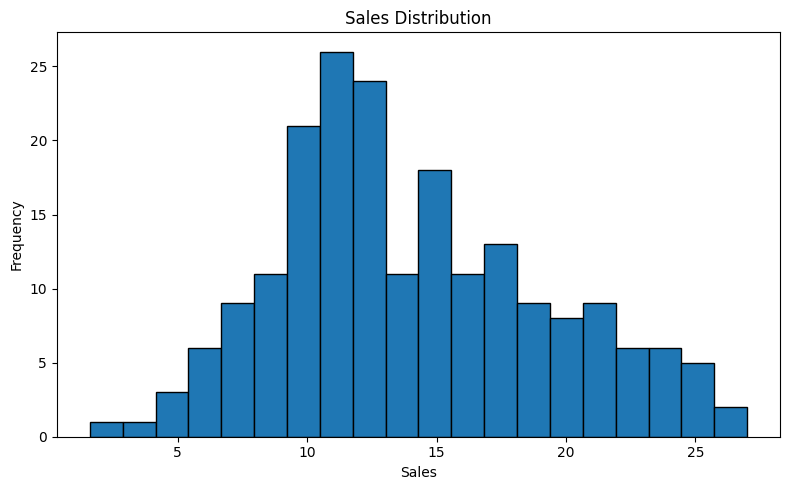

In [9]:

plt.figure(figsize=(8, 5))

plt.hist(y, bins=20, edgecolor="black")

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


In [10]:

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Unnamed: 0', 'TV', 'Radio', 'Newspaper']
Categorical features: []


In [11]:

transformers = []

if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

if not transformers:
    raise ValueError("No usable features for preprocessing.")

preprocessor = ColumnTransformer(
    transformers=transformers
)

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


In [12]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 160
Testing rows: 40


In [13]:

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Sales prediction model trained successfully!")


Sales prediction model trained successfully!


In [14]:

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("===== Sales Prediction Results =====")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")


===== Sales Prediction Results =====
MAE: 1.465
RMSE: 1.789
R2 Score: 0.899


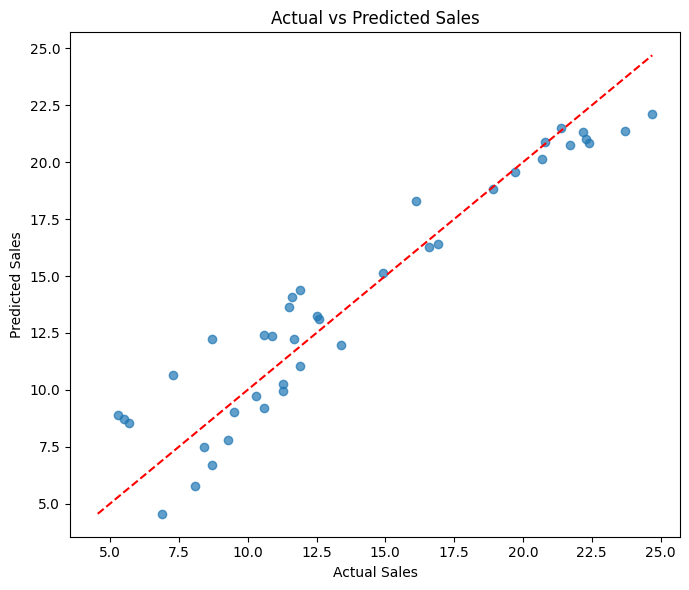

In [15]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.tight_layout()
plt.show()


In [16]:

joblib.dump(model, "sales_prediction_model.pkl")

print("Model saved as sales_prediction_model.pkl")


Model saved as sales_prediction_model.pkl


In [17]:

sample = X_test.iloc[[0]]

predicted_sales = model.predict(sample)[0]
actual_sales = y_test.iloc[0]

print("Sample input:")
display(sample)

print(f"Predicted sales: {predicted_sales:.2f}")
print(f"Actual sales: {actual_sales:.2f}")


Sample input:


,Unnamed: 0,TV,Radio,Newspaper
95,96,163.3,31.6,52.9


Predicted sales: 16.41
Actual sales: 16.90
